# Semantic Segmentation of Soil Paths in Hop Vineyards

## 1. Problem Description

Hop farms are typically organized in long parallel rows separated by soil paths that workers
and machinery use to move through the field. Identifying these paths automatically, at the
pixel level, is a foundational perception capability for several real-world applications in
precision agriculture:

- **Autonomous robot navigation.** Ground robots need to know which pixels correspond to
  drivable soil vs. plant rows so they can follow paths without damaging the crop.
- **Targeted spraying.** A vision system that reliably separates soil from canopy can
  support variable-rate herbicide/pesticide application, reducing chemical use.
- **Crop monitoring pipelines.** Masking out soil/path pixels makes downstream analyses
  (e.g. vegetation health, yield estimation) more accurate.

This project formulates the task as **binary semantic segmentation**: given an RGB image of
a hop field, predict a per-pixel mask indicating whether each pixel belongs to *soil path*
or not. We train and compare (1) a lightweight U-Net implemented from scratch, optimised for
speed via depthwise-separable convolutions, and (2) a U-Net with a pretrained MobileNetV2
encoder (transfer learning), evaluating both with IoU, Dice, and latency benchmarks.


## 2. Dataset Description

**Source:** [Spray Hops](https://universe.roboflow.com/evgeny-5zgzy/spray-hops/dataset/1),
hosted on Roboflow Universe, created by Evgeny. License: CC BY 4.0.

**Key facts:**
- 2,232 total images, each 1024×1024 pixels, RGB.
- Official split: 1,563 train (70%) / 446 validation (20%) / 223 test (10%).
- Annotations are multi-class segmentation masks; we use only the *Soil* class, making this
  a binary segmentation problem (soil-path vs. everything else).
- Export format: `png-mask-semantic` (single-channel PNGs with integer class indices).


## 3. Environment Setup


In [37]:
import os
import random
from pathlib import Path
from typing import List, Tuple, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from dotenv import load_dotenv

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"segmentation-models-pytorch version: {smp.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Fix all sources of randomness for reproducibility across runs.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data")
print(f"Using device: {DEVICE}")

PyTorch version: 2.12.1+cu130
Torchvision version: 0.27.1+cu130
segmentation-models-pytorch version: 0.5.0
CUDA available: True
GPU: NVIDIA GeForce RTX 3070
Using device: cuda


## 4. Data Acquisition

We download the dataset directly from Roboflow using their Python SDK. The API key is read
from a local `.env` file (never hardcoded or committed). We request the `png-mask-semantic`
export format, which gives one PNG mask per image with integer-coded classes.

To run this cell yourself:
1. Copy `.env.example` to `.env`.
2. Paste your Roboflow API key into `.env` as `ROBOFLOW_API_KEY=...`.
3. Run the cell below.


In [38]:
load_dotenv()
api_key = os.environ.get("ROBOFLOW_API_KEY")
assert (
    api_key
), "ROBOFLOW_API_KEY not found. Did you create a .env file from .env.example?"

from roboflow import Roboflow

rf = Roboflow(api_key=api_key)
project = rf.workspace("evgeny-5zgzy").project("spray-hops")
version = project.version(1)

# Only download if the data directory does not already exist, avoiding redundant API calls.
if not DATA_DIR.exists():
    dataset = version.download("png-mask-semantic", location=str(DATA_DIR))
else:
    print(f"'{DATA_DIR}' already exists, skipping download.")

print(sorted(p.name for p in DATA_DIR.iterdir()))

loading Roboflow workspace...
loading Roboflow project...
'data' already exists, skipping download.
['README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


## 5. Exploratory Data Analysis

Before writing the Dataset/DataLoader code, we inspect the actual downloaded files to
confirm (a) the filename convention for image/mask pairs and (b) which pixel value maps
to the *Soil* class. Roboflow's `png-mask-semantic` export can vary between versions, so
we never hardcode these values.


In [39]:
train_dir = DATA_DIR / "train"
files = sorted(os.listdir(train_dir))
print(f"Total files in train/: {len(files)}")
print("First 20 filenames:")
for f in files[:20]:
    print(" ", f)

# Roboflow usually ships a '_classes.csv' file with the pixel-value → class-name mapping.
mapping_files = [f for f in files if "class" in f.lower()]
print("\nPossible class-mapping file(s):", mapping_files)
for fname in mapping_files:
    print(f"\n--- {fname} ---")
    print((train_dir / fname).read_text())

Total files in train/: 3127
First 20 filenames:
  IMG20240723141439_jpg.rf.464694593183af03312f67c85be9d00a.jpg
  IMG20240723141439_jpg.rf.464694593183af03312f67c85be9d00a_mask.png
  IMG20240723141441_jpg.rf.b41d5a317105ce14200520d63324f7e9.jpg
  IMG20240723141441_jpg.rf.b41d5a317105ce14200520d63324f7e9_mask.png
  IMG20240723141444_jpg.rf.7257c112c5a3089caca357a7f3110039.jpg
  IMG20240723141444_jpg.rf.7257c112c5a3089caca357a7f3110039_mask.png
  IMG20240723141445_jpg.rf.d9cb539a0908037c166ea05f63136dcc.jpg
  IMG20240723141445_jpg.rf.d9cb539a0908037c166ea05f63136dcc_mask.png
  IMG20240723141447_jpg.rf.b7ec3a5c9ecc851eb4c81140be8788af.jpg
  IMG20240723141447_jpg.rf.b7ec3a5c9ecc851eb4c81140be8788af_mask.png
  IMG20240723141448_jpg.rf.fa1a74295937ca5745e8b739bdc80fe4.jpg
  IMG20240723141448_jpg.rf.fa1a74295937ca5745e8b739bdc80fe4_mask.png
  IMG20240723141456_jpg.rf.12d58b87099bc60a38db477a1539adc6.jpg
  IMG20240723141456_jpg.rf.12d58b87099bc60a38db477a1539adc6_mask.png
  IMG20240723141504_j

## 6. Data Pipeline: Discovering Classes and Pairing Files

We parse the `_classes.csv` and pair image/mask files programmatically, making the
pipeline robust to different Roboflow export conventions instead of relying on guesses.


In [40]:
def get_classes_mapping(split_dir: Path) -> dict:
    """Parse a Roboflow ``_classes.csv`` into a pixel-value → class-name mapping.

    Roboflow's ``png-mask-semantic`` format ships a CSV with the schema:
    ``pixel_value, class_name`` (one row per class, header on line 0).
    This function reads that file and returns a plain dict for easy lookup.

    Args:
        split_dir (Path): Directory for a single dataset split (e.g., ``data/train``).
            Must contain exactly one ``*class*.csv`` file.

    Returns:
        dict[int, str]: Mapping from integer pixel value to class name,
            e.g. ``{0: 'background', 1: 'Soil', 2: 'Hops'}``.

    Raises:
        FileNotFoundError: If no CSV file matching ``*class*.csv`` is found in
            ``split_dir``.

    Example::

        >>> mapping = get_classes_mapping(Path("data/train"))
        >>> print(mapping)
        {0: 'background', 1: 'Soil', 2: 'Hops', 3: 'trellis', 4: 'Weeds'}
    """
    files = os.listdir(split_dir)
    mapping_files = [
        f for f in files if "class" in f.lower() and f.lower().endswith(".csv")
    ]
    if not mapping_files:
        raise FileNotFoundError(f"No classes mapping file found in {split_dir}")

    lines = (split_dir / mapping_files[0]).read_text().strip().splitlines()
    mapping = {}
    for line in lines[1:]:  # skip the CSV header row
        parts = [p.strip() for p in line.split(",")]
        # Guard against blank/malformed lines before indexing.
        if len(parts) >= 2 and parts[0].isdigit():
            mapping[int(parts[0])] = parts[1]
    return mapping


def find_image_mask_pairs(split_dir: Path) -> List[Tuple[str, str]]:
    """Pair each RGB image file with its corresponding semantic mask PNG.

    Roboflow's ``png-mask-semantic`` export names masks as
    ``<stem>_mask.png``. This function scans the directory, separates
    mask files from image files, then matches them by stem. A fallback
    prefix search handles rare cases where the naming deviates slightly.

    Args:
        split_dir (Path): Directory for a single dataset split (e.g., ``data/train``).

    Returns:
        List[Tuple[str, str]]: List of ``(image_filename, mask_filename)`` pairs,
            both relative to ``split_dir``. Unpaired images are silently skipped.

    Example::

        >>> pairs = find_image_mask_pairs(Path("data/train"))
        >>> img, msk = pairs[0]
        >>> print(img, "->", msk)
        frame_001.jpg -> frame_001_mask.png
    """
    files = sorted(os.listdir(split_dir))

    # Identify mask files first so we can exclude them from the image list.
    mask_files = {
        f for f in files if "mask" in f.lower() and f.lower().endswith(".png")
    }
    # Also exclude metadata files (class CSVs, READMEs) from the image list.
    non_image_files = mask_files | {
        f for f in files if "class" in f.lower() or f.lower().startswith("readme")
    }
    image_files = [
        f
        for f in files
        if f not in non_image_files and f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    pairs = []
    for img_name in image_files:
        stem = Path(img_name).stem
        # Primary strategy: exact '<stem>_mask.png' convention used by Roboflow.
        candidate = f"{stem}_mask.png"
        if candidate in mask_files:
            pairs.append((img_name, candidate))
            continue
        # Fallback: prefix match for exports with slightly different suffixes.
        match = next((m for m in mask_files if Path(m).stem.startswith(stem)), None)
        if match is not None:
            pairs.append((img_name, match))
    return pairs


classes_map = get_classes_mapping(DATA_DIR / "train")
print("Discovered class mapping:", classes_map)

# Dynamically resolve the soil pixel value instead of hardcoding it, so the
# pipeline still works if Roboflow changes class ordering in a future export.
SOIL_VALUE = next(v for v, name in classes_map.items() if "soil" in name.lower())
print(f"Soil class pixel value: {SOIL_VALUE}")

train_pairs = find_image_mask_pairs(DATA_DIR / "train")
valid_pairs = find_image_mask_pairs(DATA_DIR / "valid")
test_pairs = find_image_mask_pairs(DATA_DIR / "test")
print(
    f"Pairs found -> train: {len(train_pairs)} | valid: {len(valid_pairs)} | test: {len(test_pairs)}"
)
print(
    "(Expected roughly 1563 / 446 / 223. If counts are much lower, "
    "the filename-matching heuristic may need adjusting for this export.)"
)

Discovered class mapping: {0: 'background', 1: 'Hops', 2: 'Soil', 3: 'Weeds', 4: 'trellis'}
Soil class pixel value: 2
Pairs found -> train: 1563 | valid: 446 | test: 223
(Expected roughly 1563 / 446 / 223. If counts are much lower, the filename-matching heuristic may need adjusting for this export.)


## 7. Dataset Class and Preprocessing Decisions

**Preprocessing choices:**

- **Resize to 256×256.** The originals are 1024×1024. Keeping that resolution with a
  U-Net and a batch size > 4 would exhaust 8 GB of VRAM. 256×256 preserves enough
  spatial detail to distinguish soil paths while halving memory vs. 512×512 and
  allowing batch size 16 for stable gradient estimates.
- **ImageNet normalisation** is applied to both models for a fair comparison; the
  pretrained encoder strictly requires it, and it does no harm for the scratch model.
- **Augmentations (train only):** flips and 90° rotations are appropriate for top-down
  field photos that have no canonical orientation; mild brightness/contrast and
  hue-saturation jitter address the known lighting variability in this dataset.
  We avoid aggressive cropping to preserve path-context (paths are narrow and long).


In [41]:
class SoilPathDataset(Dataset):
    """Binary segmentation dataset for hop-vineyard soil-path detection.

    Loads ``(image, mask)`` pairs from a Roboflow ``png-mask-semantic`` export
    and converts the multi-class mask into a binary ``float32`` mask where
    ``1.0`` = soil-path pixel and ``0.0`` = everything else.

    Args:
        root_dir (Path): Root data directory containing ``train/``, ``valid/``,
            and ``test/`` subdirectories.
        split (str): One of ``"train"``, ``"valid"``, or ``"test"``.
        soil_value (int): Integer pixel value in the raw mask that corresponds to
            the *Soil* class (obtained from ``_classes.csv``).
        transform (A.Compose): Albumentations pipeline applied jointly to the
            image and the mask (ensures spatial transforms stay in sync).

    Returns:
        Tuple[torch.Tensor, torch.Tensor]:
            - ``image``: Float tensor of shape ``(3, H, W)``, normalised.
            - ``mask``:  Float tensor of shape ``(1, H, W)``, values in ``{0, 1}``.

    Example::

        >>> ds = SoilPathDataset(Path("data"), "train", soil_value=1, transform=train_transform)
        >>> img, msk = ds[0]
        >>> img.shape, msk.shape
        (torch.Size([3, 256, 256]), torch.Size([1, 256, 256]))
    """

    def __init__(self, root_dir: Path, split: str, soil_value: int, transform):
        self.split_dir = Path(root_dir) / split
        self.pairs = find_image_mask_pairs(self.split_dir)
        self.soil_value = soil_value
        self.transform = transform

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, idx: int):
        img_name, mask_name = self.pairs[idx]

        # Load image as RGB (OpenCV reads BGR by default; convert immediately).
        image = cv2.cvtColor(
            cv2.imread(str(self.split_dir / img_name)), cv2.COLOR_BGR2RGB
        )
        # IMREAD_UNCHANGED preserves single-channel 8-bit masks without auto-conversion.
        raw_mask = cv2.imread(str(self.split_dir / mask_name), cv2.IMREAD_UNCHANGED)

        # Some exports save masks as 3-channel PNGs; take the first channel only.
        if raw_mask.ndim == 3:
            raw_mask = raw_mask[:, :, 0]

        # Guard against rare resolution mismatches in the export (nearest-neighbour
        # to avoid introducing non-integer class values into the mask).
        if raw_mask.shape[:2] != image.shape[:2]:
            print(
                f"Warning: resizing mismatched mask {mask_name} "
                f"{raw_mask.shape[:2]} -> {image.shape[:2]}"
            )
            raw_mask = cv2.resize(
                raw_mask,
                (image.shape[1], image.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            )

        # Collapse multi-class mask to binary: 1 where soil, 0 everywhere else.
        mask = (raw_mask == self.soil_value).astype(np.float32)

        # Albumentations handles the joint spatial transform for image and mask.
        augmented = self.transform(image=image, mask=mask)
        image = augmented["image"]
        # unsqueeze(0): add channel dim → (1, H, W) to match model output shape.
        mask = augmented["mask"].unsqueeze(0).float()
        return image, mask

In [42]:
IMG_SIZE = 256  # Input resolution; see Section 7 rationale above.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# --- Training augmentations ---
# Geometric: flips + 90° rotations → no canonical orientation in overhead field shots.
# Photometric: mild brightness/contrast + hue-saturation to handle lighting variability.
# No cropping: paths are narrow strips; aggressive crops risk removing all context.
train_transform = A.Compose(
    [
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.2),
        A.RandomRotate90(p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
        A.HueSaturationValue(
            hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=10, p=0.3
        ),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ]
)

# --- Evaluation transform: only resize + normalise; no randomness ---
eval_transform = A.Compose(
    [
        A.Resize(IMG_SIZE, IMG_SIZE),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ]
)

Train: 1563 | Valid: 446 | Test: 223
Image batch shape: torch.Size([16, 3, 256, 256]) | Mask batch shape: torch.Size([16, 1, 256, 256])
Soil pixel fraction in this batch: 0.29763317108154297


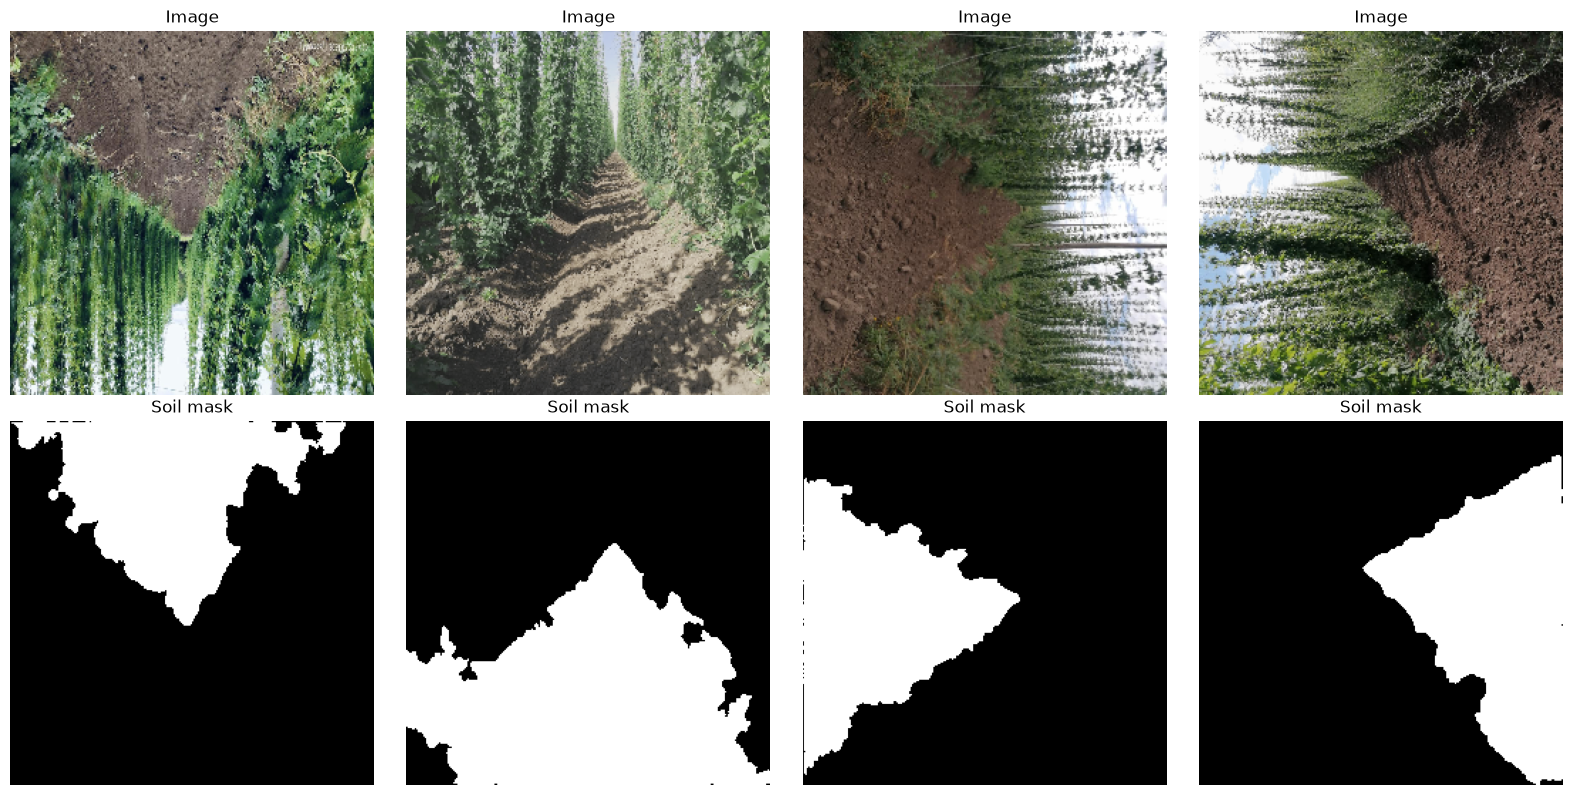

In [43]:
# Batch size 16 at 256×256 with mixed precision fits comfortably within 8 GB VRAM.
BATCH_SIZE = 16

train_ds = SoilPathDataset(DATA_DIR, "train", SOIL_VALUE, train_transform)
valid_ds = SoilPathDataset(DATA_DIR, "valid", SOIL_VALUE, eval_transform)
test_ds = SoilPathDataset(DATA_DIR, "test", SOIL_VALUE, eval_transform)
print(f"Train: {len(train_ds)} | Valid: {len(valid_ds)} | Test: {len(test_ds)}")

# num_workers=4 feeds the GPU without becoming the bottleneck on a typical 8-core CPU.
# persistent_workers=True avoids the overhead of spawning/destroying worker processes
# between epochs — a meaningful speedup when there are many small batches per epoch.
# pin_memory=True allows async host→device DMA transfers, overlapping I/O and compute.
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
)
valid_loader = DataLoader(
    valid_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
)
test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
)

images, masks = next(iter(train_loader))
print("Image batch shape:", images.shape, "| Mask batch shape:", masks.shape)
print("Soil pixel fraction in this batch:", masks.mean().item())


def denormalize(img_tensor: torch.Tensor) -> np.ndarray:
    """Reverse ImageNet normalisation for visualisation.

    Args:
        img_tensor (torch.Tensor): Normalised image tensor of shape ``(3, H, W)``.

    Returns:
        np.ndarray: Float32 array of shape ``(H, W, 3)`` with values in ``[0, 1]``,
            suitable for ``plt.imshow``.
    """
    img = img_tensor.permute(1, 2, 0).cpu().numpy()
    img = img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(img, 0, 1)


fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i in range(4):
    axes[0, i].imshow(denormalize(images[i]))
    axes[0, i].set_title("Image")
    axes[0, i].axis("off")
    axes[1, i].imshow(masks[i, 0], cmap="gray")
    axes[1, i].set_title("Soil mask")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

## 8. Model 1: Lightweight U-Net from Scratch (Speed-Optimised)

**Design goal: fast inference with a small parameter count.**

We replace the standard double-3×3-conv block with **depthwise-separable convolutions**
(MobileNet-style): a depthwise 3×3 conv (one filter per input channel) followed by a
pointwise 1×1 conv (mixes channels). This factorisation cuts FLOPs and parameters by
roughly `k²` (≈9×) vs. a full convolution at the same channel width, while preserving
most of the representational power for the binary segmentation task at hand.

We also reduce `base_channels` from 32 → 16. Combined with depthwise-separable convs,
the resulting model is ≈4-8× smaller and faster than the vanilla U-Net at the cost of
some capacity — a reasonable trade-off for a binary task on 256×256 inputs.


In [44]:
class DepthwiseSeparableConv(nn.Module):
    """Single depthwise-separable convolution block: DW-3×3 → BN → ReLU → PW-1×1 → BN → ReLU.

    Factorises a standard ``k×k`` convolution into a **depthwise** (per-channel spatial
    filter) and a **pointwise** (channel mixer) convolution. At ``k=3`` this reduces
    FLOPs and parameter count by ~9× relative to an equivalent full convolution, at the
    cost of slightly reduced mixing capacity.

    Args:
        in_channels (int): Number of input channels.
        out_channels (int): Number of output channels produced by the pointwise conv.
        stride (int): Stride applied to the depthwise conv. Default: ``1``.

    Shape:
        - Input:  ``(N, in_channels, H, W)``
        - Output: ``(N, out_channels, H // stride, W // stride)``

    Example::

        >>> block = DepthwiseSeparableConv(64, 128)
        >>> x = torch.randn(2, 64, 32, 32)
        >>> block(x).shape
        torch.Size([2, 128, 32, 32])
    """

    def __init__(self, in_channels: int, out_channels: int, stride: int = 1):
        super().__init__()
        # Depthwise: groups=in_channels → each input channel has its own spatial filter.
        self.depthwise = nn.Conv2d(
            in_channels,
            in_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            groups=in_channels,
            bias=False,
        )
        self.bn1 = nn.BatchNorm2d(in_channels)
        # Pointwise: 1×1 conv mixes information across channels.
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)  # inplace saves activation memory

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu(self.bn1(self.depthwise(x)))
        x = self.relu(self.bn2(self.pointwise(x)))
        return x


class LightDoubleConv(nn.Module):
    """Two stacked :class:`DepthwiseSeparableConv` blocks, analogous to U-Net's double-conv.

    Using two successive depthwise-separable convolutions (rather than one) enlarges the
    effective receptive field and deepens the non-linear transform at each resolution level
    without the quadratic parameter cost of full convolutions.

    Args:
        in_channels (int): Number of input channels.
        out_channels (int): Number of output channels.

    Shape:
        - Input:  ``(N, in_channels, H, W)``
        - Output: ``(N, out_channels, H, W)``

    Example::

        >>> block = LightDoubleConv(32, 64)
        >>> block(torch.randn(2, 32, 64, 64)).shape
        torch.Size([2, 64, 64, 64])
    """

    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.conv1 = DepthwiseSeparableConv(in_channels, out_channels)
        self.conv2 = DepthwiseSeparableConv(out_channels, out_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv2(self.conv1(x))


class LightUNet(nn.Module):
    """Speed-optimised U-Net using depthwise-separable convolutions.

    Implements the classic encoder-decoder U-Net topology (Ronneberger et al., 2015)
    with two modifications for faster inference and lower memory consumption:

    1. **Depthwise-separable convolutions** (via :class:`LightDoubleConv`) replace all
       standard 3×3 convolutions, reducing FLOPs ≈9× per conv block.
    2. **Reduced base width** (``base_channels=16`` instead of 64) further cuts the
       parameter count. The channel sizes at each depth are
       ``[c, 2c, 4c, 8c]`` encoder + ``16c`` bottleneck, symmetric decoder.

    The result is a model that runs significantly faster at inference time while
    remaining sufficient for binary segmentation on 256×256 inputs.

    Args:
        in_channels (int): Number of input image channels. Default: ``3`` (RGB).
        out_channels (int): Number of output logit channels. Default: ``1`` (binary).
        base_channels (int): Width multiplier; number of filters in the first encoder
            block. All deeper blocks are multiples of this value. Default: ``16``.

    Shape:
        - Input:  ``(N, in_channels, H, W)``
        - Output: ``(N, out_channels, H, W)`` — raw logits (no sigmoid).

    Example::

        >>> model = LightUNet(in_channels=3, out_channels=1, base_channels=16)
        >>> x = torch.randn(2, 3, 256, 256)
        >>> model(x).shape
        torch.Size([2, 1, 256, 256])
    """

    def __init__(
        self,
        in_channels: int = 3,
        out_channels: int = 1,
        base_channels: int = 16,
    ):
        super().__init__()
        c = base_channels  # shorthand; channel widths: c, 2c, 4c, 8c, 16c

        # --- Encoder: progressively double channels, halve spatial dims via pooling ---
        self.enc1 = LightDoubleConv(in_channels, c)  # (N, 3, H, W)    → (N, c,   H, W)
        self.enc2 = LightDoubleConv(c, c * 2)  # (N, c,   H/2, W/2) → (N, 2c, H/2, W/2)
        self.enc3 = LightDoubleConv(c * 2, c * 4)  # → (N, 4c, H/4, W/4)
        self.enc4 = LightDoubleConv(c * 4, c * 8)  # → (N, 8c, H/8, W/8)
        self.pool = nn.MaxPool2d(2)  # halves H and W

        # --- Bottleneck: deepest representation, no skip connection ---
        self.bottleneck = LightDoubleConv(c * 8, c * 16)  # → (N, 16c, H/16, W/16)

        # --- Decoder: upsample + concatenate encoder skip, then double-conv ---
        # ConvTranspose2d(kernel=2, stride=2) doubles H and W exactly.
        self.up4 = nn.ConvTranspose2d(c * 16, c * 8, kernel_size=2, stride=2)
        self.dec4 = LightDoubleConv(c * 16, c * 8)  # input = up(b) ++ e4 → 2*(c*8)
        self.up3 = nn.ConvTranspose2d(c * 8, c * 4, kernel_size=2, stride=2)
        self.dec3 = LightDoubleConv(c * 8, c * 4)
        self.up2 = nn.ConvTranspose2d(c * 4, c * 2, kernel_size=2, stride=2)
        self.dec2 = LightDoubleConv(c * 4, c * 2)
        self.up1 = nn.ConvTranspose2d(c * 2, c, kernel_size=2, stride=2)
        self.dec1 = LightDoubleConv(c * 2, c)

        # --- Output head: 1×1 conv collapses channels to the number of classes ---
        self.out_conv = nn.Conv2d(c, out_channels, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Run a forward pass through the U-Net.

        Args:
            x (torch.Tensor): Input image batch of shape ``(N, in_channels, H, W)``.

        Returns:
            torch.Tensor: Raw logit map of shape ``(N, out_channels, H, W)``.
                Apply ``torch.sigmoid`` to obtain probabilities.
        """
        # --- Encoder: save activations for skip connections ---
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        # --- Decoder: upsample then concatenate the corresponding encoder skip ---
        # torch.cat along dim=1 (channels) merges upsampled feature with encoder skip.
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out_conv(d1)  # raw logits; sigmoid applied in loss / at inference


# --- Sanity check: confirm shapes and report parameter count ---
_sanity_model = LightUNet().to(DEVICE)
n_params = sum(p.numel() for p in _sanity_model.parameters())
print(f"LightUNet parameters: {n_params:,}")
with torch.no_grad():
    sample = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
    out = _sanity_model(sample)
    print("Forward pass output shape:", out.shape)
del _sanity_model

LightUNet parameters: 389,474
Forward pass output shape: torch.Size([2, 1, 256, 256])


## 9. Model 2: U-Net with Pretrained MobileNetV2 Encoder (Transfer Learning)

**Why MobileNetV2 instead of ResNet34?**
MobileNetV2 was explicitly designed for mobile/edge inference: its inverted-residual
blocks with depthwise-separable convolutions give it a much lower FLOP count than
ResNet34 at comparable accuracy on ImageNet. As our second model aims for *speed*,
MobileNetV2 is a better backbone choice than ResNet34 for production / embedded use.

**Freezing strategy:** We freeze the entire encoder for a short warm-up phase (first 5
epochs) so the randomly-initialised decoder can learn to consume pretrained features
before large early gradients corrupt them. After warm-up, we unfreeze end-to-end but
apply a 10× lower LR to the encoder, preserving useful ImageNet weights while still
allowing task-specific fine-tuning.


In [45]:
ENCODER_NAME = "mobilenet_v2"  # lightweight encoder; ~3.4 M params vs ResNet34's ~21 M


def set_encoder_trainable(model: nn.Module, trainable: bool) -> None:
    """Freeze or unfreeze all parameters in the SMP model's encoder.

    Used to implement a warm-up schedule: train the decoder first (encoder frozen),
    then unfreeze the encoder for end-to-end fine-tuning at a lower learning rate.

    Args:
        model (nn.Module): A ``segmentation_models_pytorch`` model that exposes
            a ``.encoder`` attribute (e.g., ``smp.Unet``).
        trainable (bool): If ``True``, gradients are enabled for all encoder
            parameters; if ``False``, encoder parameters are frozen.

    Example::

        >>> model = smp.Unet(encoder_name="mobilenet_v2", encoder_weights="imagenet", ...)
        >>> set_encoder_trainable(model, trainable=False)  # freeze encoder
        >>> set_encoder_trainable(model, trainable=True)   # unfreeze for fine-tuning
    """
    for param in model.encoder.parameters():
        param.requires_grad = trainable


_sanity_model = smp.Unet(
    encoder_name=ENCODER_NAME, encoder_weights="imagenet", in_channels=3, classes=1
).to(DEVICE)
set_encoder_trainable(_sanity_model, trainable=False)
n_total = sum(p.numel() for p in _sanity_model.parameters())
n_trainable = sum(p.numel() for p in _sanity_model.parameters() if p.requires_grad)
print(
    f"Total params: {n_total:,} | Trainable during warm-up (decoder only): {n_trainable:,}"
)
del _sanity_model

Total params: 6,628,945 | Trainable during warm-up (decoder only): 4,405,073


## 10. Loss Function and Evaluation Metrics

**Loss — BCE + soft Dice (combined):**
- `BCEWithLogitsLoss` provides a stable per-pixel cross-entropy signal across the
  entire image, including the (usually large) background region.
- Soft Dice loss directly optimises the overlap between prediction and ground truth,
  making it robust to the foreground/background class imbalance typical of path masks.
- Equal weighting (0.5 / 0.5) is a common starting point; shifting toward Dice
  would help further if class imbalance turns out to be severe.

**Metrics — IoU and Dice:**
Both are computed on binarised predictions (threshold 0.5) as required by the project
brief. IoU is the stricter metric (penalises FP and FN symmetrically); Dice is used as
the checkpoint criterion because it is numerically smoother to optimise against.


In [46]:
class BCEDiceLoss(nn.Module):
    """Combined Binary Cross-Entropy and soft Dice loss for binary segmentation.

    Computes ``bce_weight * BCE + (1 - bce_weight) * Dice``. BCE provides a
    pixel-wise gradient across the full image; soft Dice directly optimises the
    overlap measure and is robust to class imbalance.

    Args:
        bce_weight (float): Mixing coefficient in ``[0, 1]``. At ``0.5`` both
            terms contribute equally. Higher values weight BCE more heavily.
            Default: ``0.5``.

    Shape:
        - logits:  ``(N, 1, H, W)`` — raw model output (before sigmoid).
        - targets: ``(N, 1, H, W)`` — binary float mask in ``{0.0, 1.0}``.

    Example::

        >>> criterion = BCEDiceLoss(bce_weight=0.5)
        >>> logits = torch.randn(4, 1, 256, 256)
        >>> targets = torch.randint(0, 2, (4, 1, 256, 256)).float()
        >>> loss = criterion(logits, targets)
    """

    def __init__(self, bce_weight: float = 0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight

    def dice_loss(
        self,
        logits: torch.Tensor,
        targets: torch.Tensor,
        eps: float = 1e-7,
    ) -> torch.Tensor:
        """Compute soft Dice loss per batch element, then average.

        Args:
            logits (torch.Tensor): Raw model outputs of shape ``(N, 1, H, W)``.
            targets (torch.Tensor): Binary float masks of shape ``(N, 1, H, W)``.
            eps (float): Small constant for numerical stability. Default: ``1e-7``.

        Returns:
            torch.Tensor: Scalar soft Dice loss (``1 - mean_dice``).
        """
        # Sigmoid converts logits to probabilities; reshape to (N, H*W) for easy sums.
        probs = torch.sigmoid(logits).reshape(logits.size(0), -1)
        targets = targets.reshape(targets.size(0), -1)
        intersection = (probs * targets).sum(dim=1)  # per-sample TP area
        union = probs.sum(dim=1) + targets.sum(dim=1)  # pred area + true area
        dice = (2 * intersection + eps) / (union + eps)
        return 1 - dice.mean()  # 0 = perfect overlap, 1 = no overlap

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        """Compute the combined BCE + Dice loss.

        Args:
            logits (torch.Tensor): Raw model outputs of shape ``(N, 1, H, W)``.
            targets (torch.Tensor): Binary float masks of shape ``(N, 1, H, W)``.

        Returns:
            torch.Tensor: Scalar combined loss value.
        """
        bce = self.bce(logits, targets)
        dice = self.dice_loss(logits, targets)
        return self.bce_weight * bce + (1 - self.bce_weight) * dice


@torch.no_grad()
def iou_dice_scores(
    logits: torch.Tensor,
    targets: torch.Tensor,
    threshold: float = 0.5,
    eps: float = 1e-7,
) -> Tuple[float, float]:
    """Compute batch-averaged binary IoU and Dice scores from raw logits.

    Binarises predictions at ``threshold`` and computes intersection-over-union
    and Dice coefficient per sample, then returns the batch mean of each.

    Args:
        logits (torch.Tensor): Raw model outputs of shape ``(N, 1, H, W)``.
        targets (torch.Tensor): Binary float masks of shape ``(N, 1, H, W)``.
        threshold (float): Sigmoid probability threshold for binarisation. Default: ``0.5``.
        eps (float): Small constant to avoid division by zero. Default: ``1e-7``.

    Returns:
        Tuple[float, float]: ``(mean_iou, mean_dice)`` averaged across the batch.

    Example::

        >>> iou, dice = iou_dice_scores(logits, masks)
        >>> print(f"IoU: {iou:.4f} | Dice: {dice:.4f}")
    """
    # Binarise: convert sigmoid probabilities to 0/1 predictions.
    preds = (torch.sigmoid(logits) > threshold).float().reshape(logits.size(0), -1)
    targets = targets.reshape(targets.size(0), -1)

    intersection = (preds * targets).sum(dim=1)  # per-sample true positives
    union = preds.sum(dim=1) + targets.sum(dim=1) - intersection

    iou = (intersection + eps) / (union + eps)
    dice = (2 * intersection + eps) / (preds.sum(dim=1) + targets.sum(dim=1) + eps)
    return iou.mean().item(), dice.mean().item()

## 11. Training Loop

Standard epoch loop with:
- **Adam** optimiser — adaptive learning rates suit the mixed encoder/decoder update
  magnitudes, especially during the warm-up phase.
- **ReduceLROnPlateau** on validation loss — automatically backs off the LR when
  the model stops improving, avoiding manual step scheduling.
- **Automatic mixed precision (AMP)** — `torch.autocast` + `GradScaler` compute
  forward/backward in float16 where safe, halving memory and improving throughput
  on Tensor Core GPUs. The scaler compensates for float16's limited dynamic range.
- **Best-model checkpointing** by validation Dice — restores the peak-performance
  snapshot at test time, independent of when training was stopped.
- **`unfreeze_epoch`** (optional) — triggers the warm-up → fine-tune transition for
  the pretrained model; silently unused for the scratch model.


In [47]:
def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    scaler: torch.amp.GradScaler,
) -> float:
    """Run one full training epoch and return the mean loss over all samples.

    Iterates the dataloader, computes the forward pass under AMP, backpropagates
    with gradient scaling, and steps the optimiser.

    Args:
        model (nn.Module): Segmentation model to train.
        loader (DataLoader): Training dataloader yielding ``(images, masks)`` batches.
        optimizer (torch.optim.Optimizer): Optimiser (e.g., Adam) for parameter updates.
        criterion (nn.Module): Loss function (e.g., :class:`BCEDiceLoss`).
        device (torch.device): Target device (``"cuda"`` or ``"cpu"``).
        scaler (torch.amp.GradScaler): AMP gradient scaler; handles float16 underflow.

    Returns:
        float: Dataset-weighted mean training loss for this epoch.
    """
    model.train()
    running_loss = 0.0
    for images, masks in loader:
        # Move data to GPU asynchronously (non_blocking=True exploits pin_memory).
        images, masks = images.to(device, non_blocking=True), masks.to(
            device, non_blocking=True
        )

        optimizer.zero_grad()
        # autocast: ops run in float16 where safe (matmuls, convs); BN stays in float32.
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            logits = model(images)
            loss = criterion(logits, masks)

        # scale → backward → unscale → step → update: standard AMP pattern.
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate dataset-weighted loss (multiply by batch size, not batch count).
        running_loss += loss.item() * images.size(0)

    return running_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> Tuple[float, float, float]:
    """Evaluate the model on a dataloader and return loss, IoU, and Dice.

    Args:
        model (nn.Module): Segmentation model in eval mode.
        loader (DataLoader): Dataloader yielding ``(images, masks)`` batches.
        criterion (nn.Module): Loss function for computing the reported loss.
        device (torch.device): Target device.

    Returns:
        Tuple[float, float, float]:
            - ``mean_loss``: Dataset-weighted mean loss.
            - ``mean_iou``:  Batch-averaged IoU (at threshold 0.5).
            - ``mean_dice``: Batch-averaged Dice (at threshold 0.5).
    """
    model.eval()
    running_loss, running_iou, running_dice, n_batches = 0.0, 0.0, 0.0, 0
    for images, masks in loader:
        images, masks = images.to(device, non_blocking=True), masks.to(
            device, non_blocking=True
        )
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            logits = model(images)
            loss = criterion(logits, masks)

        iou, dice = iou_dice_scores(logits, masks)
        running_loss += loss.item() * images.size(0)
        running_iou += iou  # batch mean; divided by n_batches at the end
        running_dice += dice
        n_batches += 1

    return (
        running_loss / len(loader.dataset),
        running_iou / n_batches,
        running_dice / n_batches,
    )


def fit(
    model: nn.Module,
    train_loader: DataLoader,
    valid_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    epochs: int,
    scheduler: Optional[object] = None,
    checkpoint_path: Optional[str] = None,
    unfreeze_epoch: Optional[int] = None,
) -> dict:
    """Full training loop with checkpointing and optional encoder warm-up schedule.

    Trains ``model`` for ``epochs`` epochs, evaluating on ``valid_loader`` after each
    epoch and saving the best checkpoint (by validation Dice). If ``unfreeze_epoch`` is
    provided, the model's encoder is unfrozen at that epoch and added to the optimiser
    at a 10× lower learning rate (implements the warm-up / fine-tune schedule).

    Args:
        model (nn.Module): Segmentation model to train.
        train_loader (DataLoader): Training dataloader.
        valid_loader (DataLoader): Validation dataloader.
        optimizer (torch.optim.Optimizer): Optimiser. For the pretrained model, only
            decoder parameters should be in the initial param groups; the encoder is
            added automatically at ``unfreeze_epoch``.
        criterion (nn.Module): Combined loss function.
        device (torch.device): Target device.
        epochs (int): Total number of training epochs.
        scheduler (optional): LR scheduler with a ``.step(metric)`` interface
            (e.g., ``ReduceLROnPlateau``). ``None`` disables scheduling.
        checkpoint_path (str, optional): File path to save the best model weights.
            ``None`` disables checkpointing.
        unfreeze_epoch (int, optional): Epoch at which to unfreeze the encoder and
            begin end-to-end fine-tuning. ``None`` keeps the encoder frozen throughout
            (or is simply not applicable for the scratch model).

    Returns:
        dict: Training history with keys ``"train_loss"``, ``"val_loss"``,
            ``"val_iou"``, ``"val_dice"``; each maps to a list of per-epoch values.
    """
    history: dict = {"train_loss": [], "val_loss": [], "val_iou": [], "val_dice": []}
    best_dice = 0.0
    # GradScaler is a no-op on CPU; enabled flag prevents errors in CPU-only mode.
    scaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))

    for epoch in range(1, epochs + 1):
        # --- Warm-up → fine-tune transition for the pretrained encoder model ---
        if unfreeze_epoch is not None and epoch == unfreeze_epoch:
            print(f"Epoch {epoch}: unfreezing encoder for end-to-end fine-tuning.")
            set_encoder_trainable(model, trainable=True)
            # Add encoder params as a separate param group at 10× lower LR to
            # preserve the pretrained representation while allowing task adaptation.
            optimizer.add_param_group(
                {
                    "params": model.encoder.parameters(),
                    "lr": optimizer.param_groups[0]["lr"] * 0.1,
                }
            )

        train_loss = train_one_epoch(
            model, train_loader, optimizer, criterion, device, scaler
        )
        val_loss, val_iou, val_dice = evaluate(model, valid_loader, criterion, device)

        # Step the LR scheduler based on validation loss (lower is better).
        if scheduler is not None:
            scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_iou"].append(val_iou)
        history["val_dice"].append(val_dice)

        print(
            f"Epoch {epoch:>3}/{epochs} | train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | val_IoU={val_iou:.4f} | val_Dice={val_dice:.4f}"
        )

        # Save whenever we set a new best validation Dice score.
        if checkpoint_path is not None and val_dice > best_dice:
            best_dice = val_dice
            torch.save(model.state_dict(), checkpoint_path)
            print(f"  -> new best model saved (val_Dice={val_dice:.4f})")

    return history

## 12. Training the Models

**Hyperparameter rationale:**
- Batch size 16 at 256×256 with AMP fits comfortably in 8 GB VRAM.
- 25 epochs with `ReduceLROnPlateau` (patience=3, factor=0.5) allows convergence
  without manual LR tuning; the scheduler backs off automatically on plateaus.
- 5-epoch decoder-only warm-up for the pretrained model follows the justification
  in Section 9.
- `LightUNet` starts with `base_channels=16` to stay within the speed budget;
  `mobilenet_v2` is ~6× fewer params than ResNet34 at comparable ImageNet accuracy.


In [48]:
EPOCHS = 25
criterion = BCEDiceLoss(bce_weight=0.5)

# --- Model 1: Lightweight U-Net from scratch ---
model_scratch = LightUNet(in_channels=3, out_channels=1, base_channels=16).to(DEVICE)
optimizer_scratch = torch.optim.Adam(model_scratch.parameters(), lr=1e-3)
# ReduceLROnPlateau: halve LR after 3 epochs without validation loss improvement.
scheduler_scratch = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_scratch, mode="min", factor=0.5, patience=3
)

print("Training LightUNet from scratch...")
history_scratch = fit(
    model_scratch,
    train_loader,
    valid_loader,
    optimizer_scratch,
    criterion,
    DEVICE,
    epochs=EPOCHS,
    scheduler=scheduler_scratch,
    checkpoint_path="best_lightunet_scratch.pt",
)

Training LightUNet from scratch...
Epoch   1/25 | train_loss=0.4325 | val_loss=0.2446 | val_IoU=0.8104 | val_Dice=0.8871
  -> new best model saved (val_Dice=0.8871)
Epoch   2/25 | train_loss=0.2161 | val_loss=0.1433 | val_IoU=0.8666 | val_Dice=0.9227
  -> new best model saved (val_Dice=0.9227)
Epoch   3/25 | train_loss=0.1573 | val_loss=0.1198 | val_IoU=0.8747 | val_Dice=0.9281
  -> new best model saved (val_Dice=0.9281)
Epoch   4/25 | train_loss=0.1377 | val_loss=0.1174 | val_IoU=0.8677 | val_Dice=0.9252
Epoch   5/25 | train_loss=0.1258 | val_loss=0.0973 | val_IoU=0.8872 | val_Dice=0.9347
  -> new best model saved (val_Dice=0.9347)
Epoch   6/25 | train_loss=0.1134 | val_loss=0.0990 | val_IoU=0.8826 | val_Dice=0.9324
Epoch   7/25 | train_loss=0.1107 | val_loss=0.0908 | val_IoU=0.8933 | val_Dice=0.9399
  -> new best model saved (val_Dice=0.9399)
Epoch   8/25 | train_loss=0.1072 | val_loss=0.1017 | val_IoU=0.8811 | val_Dice=0.9326
Epoch   9/25 | train_loss=0.1036 | val_loss=0.0868 | val_

In [49]:
WARMUP_EPOCHS = 5  # epochs to keep the encoder frozen before fine-tuning end-to-end

# --- Model 2: U-Net with pretrained MobileNetV2 encoder ---
model_pretrained = smp.Unet(
    encoder_name=ENCODER_NAME, encoder_weights="imagenet", in_channels=3, classes=1
).to(DEVICE)
# Freeze encoder; only the decoder params are trained during warm-up.
set_encoder_trainable(model_pretrained, trainable=False)

optimizer_pretrained = torch.optim.Adam(
    [p for p in model_pretrained.parameters() if p.requires_grad],
    lr=1e-3,
)
scheduler_pretrained = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_pretrained, mode="min", factor=0.5, patience=3
)

print("Training U-Net with pretrained MobileNetV2 encoder...")
history_pretrained = fit(
    model_pretrained,
    train_loader,
    valid_loader,
    optimizer_pretrained,
    criterion,
    DEVICE,
    epochs=EPOCHS,
    scheduler=scheduler_pretrained,
    checkpoint_path="best_lightunet_pretrained.pt",
    unfreeze_epoch=WARMUP_EPOCHS + 1,  # switch to end-to-end at epoch 6
)

Training U-Net with pretrained MobileNetV2 encoder...
Epoch   1/25 | train_loss=0.1623 | val_loss=0.0848 | val_IoU=0.9077 | val_Dice=0.9478
  -> new best model saved (val_Dice=0.9478)
Epoch   2/25 | train_loss=0.0918 | val_loss=0.0789 | val_IoU=0.9109 | val_Dice=0.9497
  -> new best model saved (val_Dice=0.9497)
Epoch   3/25 | train_loss=0.0859 | val_loss=0.0734 | val_IoU=0.9142 | val_Dice=0.9514
  -> new best model saved (val_Dice=0.9514)
Epoch   4/25 | train_loss=0.0823 | val_loss=0.0718 | val_IoU=0.9168 | val_Dice=0.9529
  -> new best model saved (val_Dice=0.9529)
Epoch   5/25 | train_loss=0.0804 | val_loss=0.0691 | val_IoU=0.9185 | val_Dice=0.9537
  -> new best model saved (val_Dice=0.9537)
Epoch 6: unfreezing encoder for end-to-end fine-tuning.
Epoch   6/25 | train_loss=0.0787 | val_loss=0.0654 | val_IoU=0.9237 | val_Dice=0.9567
  -> new best model saved (val_Dice=0.9567)
Epoch   7/25 | train_loss=0.0712 | val_loss=0.0654 | val_IoU=0.9251 | val_Dice=0.9574
  -> new best model save

## 13. Inference Speed Benchmark

We measure per-image latency for both models to confirm the speed goal is met.
The benchmark uses a single batch of 16 images at 256×256 with 100 warm-up + 200
timed iterations; GPU timing uses CUDA events for accuracy (avoids Python overhead).


In [50]:
@torch.no_grad()
def benchmark_latency(
    model: nn.Module,
    device: torch.device,
    img_size: int = 256,
    batch_size: int = 1,
    warmup: int = 100,
    iterations: int = 200,
) -> float:
    """Measure mean per-image inference latency in milliseconds.

    Runs ``warmup`` forward passes to prime the CUDA kernel cache, then times
    ``iterations`` passes using CUDA events (GPU) or ``time.perf_counter`` (CPU).

    Args:
        model (nn.Module): Model to benchmark (must already be on ``device``).
        device (torch.device): Device the model lives on.
        img_size (int): Spatial resolution of the dummy input. Default: ``256``.
        batch_size (int): Batch size for the benchmark. Default: ``1`` (single-image
            latency — most relevant for real-time use cases).
        warmup (int): Number of warm-up passes before timing starts. Default: ``100``.
        iterations (int): Number of timed passes. Default: ``200``.

    Returns:
        float: Mean per-image latency in milliseconds.

    Example::

        >>> lat = benchmark_latency(model_scratch, DEVICE)
        >>> print(f"Latency: {lat:.2f} ms/image")
    """
    import time

    model.eval()
    dummy = torch.randn(batch_size, 3, img_size, img_size).to(device)

    # Warm-up: let CUDA JIT-compile kernels and fill caches before timing.
    for _ in range(warmup):
        _ = model(dummy)
    if device.type == "cuda":
        torch.cuda.synchronize()

    if device.type == "cuda":
        # CUDA events give microsecond-accurate GPU timing, independent of Python GIL.
        start_event = torch.cuda.Event(enable_timing=True)
        end_event = torch.cuda.Event(enable_timing=True)
        start_event.record()
        for _ in range(iterations):
            _ = model(dummy)
        end_event.record()
        torch.cuda.synchronize()
        total_ms = start_event.elapsed_time(end_event)
    else:
        t0 = time.perf_counter()
        for _ in range(iterations):
            _ = model(dummy)
        total_ms = (time.perf_counter() - t0) * 1000

    return total_ms / (iterations * batch_size)


lat_scratch = benchmark_latency(model_scratch, DEVICE)
lat_pretrained = benchmark_latency(model_pretrained, DEVICE)
print(f"LightUNet (scratch)   — latency: {lat_scratch:.2f} ms/image")
print(f"U-Net (MobileNetV2)   — latency: {lat_pretrained:.2f} ms/image")

LightUNet (scratch)   — latency: 5.42 ms/image
U-Net (MobileNetV2)   — latency: 10.05 ms/image


## 14. Visualisations and Evaluation

Loss/metric curves for both models, final test-set metrics, latency comparison,
normalised confusion matrices, and qualitative prediction samples.


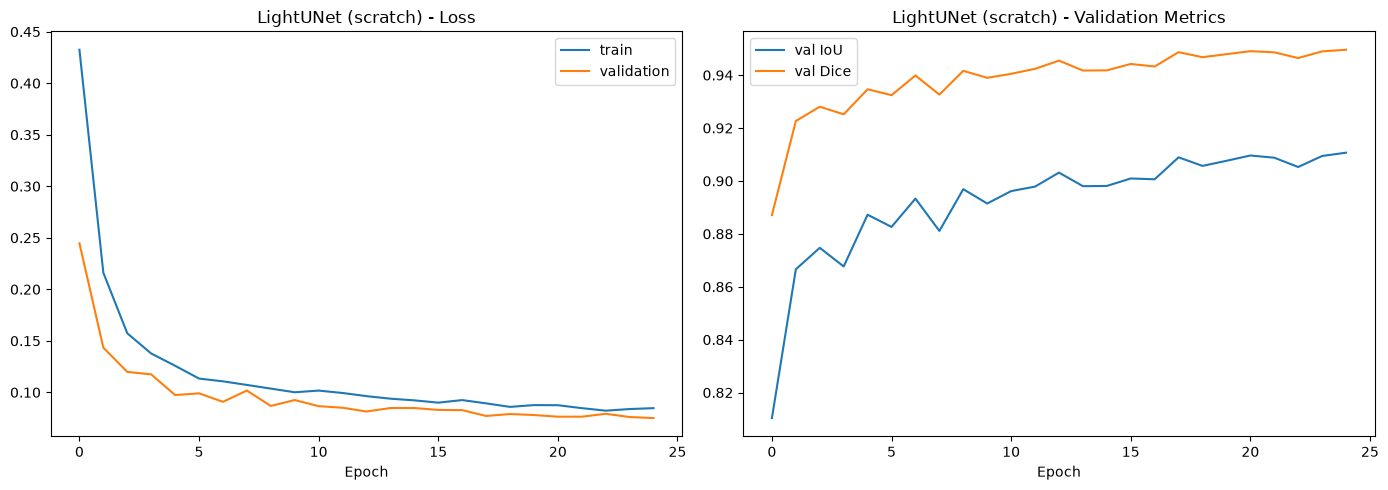

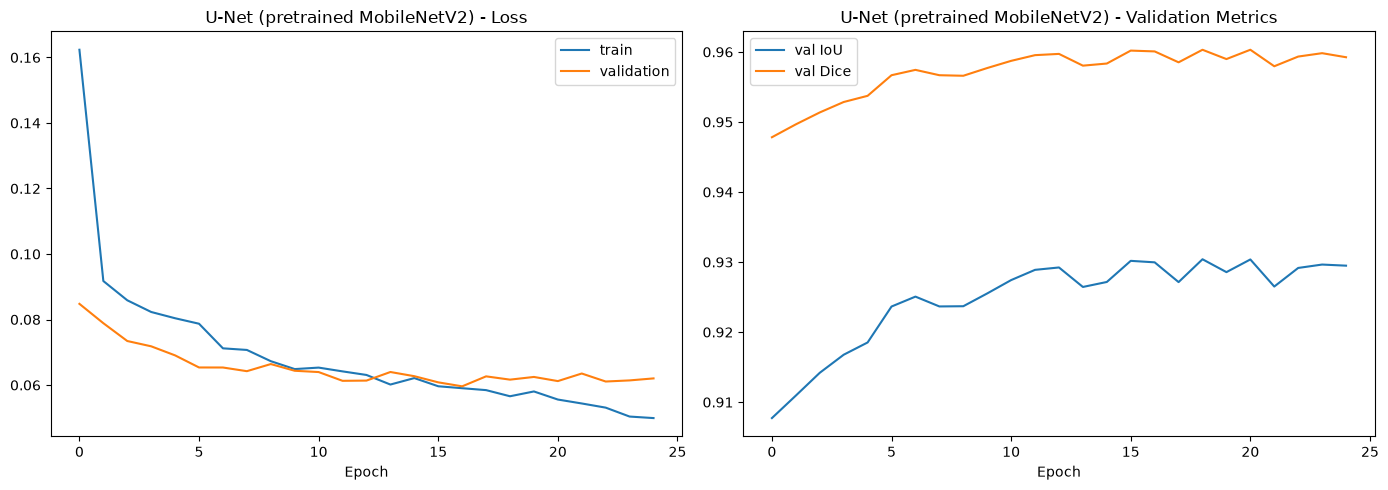

In [51]:
def plot_history(history: dict, title: str) -> None:
    """Plot training/validation loss and validation IoU/Dice curves side by side.

    Args:
        history (dict): Output of :func:`fit`; must contain keys
            ``"train_loss"``, ``"val_loss"``, ``"val_iou"``, ``"val_dice"``.
        title (str): Figure super-title identifying the model.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["val_iou"], label="val IoU")
    axes[1].plot(history["val_dice"], label="val Dice")
    axes[1].set_title(f"{title} - Validation Metrics")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


plot_history(history_scratch, "LightUNet (scratch)")
plot_history(history_pretrained, "U-Net (pretrained MobileNetV2)")

In [52]:
# Load the best checkpoints (by val Dice) saved during training.
model_scratch.load_state_dict(
    torch.load("best_lightunet_scratch.pt", map_location=DEVICE)
)
model_pretrained.load_state_dict(
    torch.load("best_lightunet_pretrained.pt", map_location=DEVICE)
)

test_loss_s, test_iou_s, test_dice_s = evaluate(
    model_scratch, test_loader, criterion, DEVICE
)
test_loss_p, test_iou_p, test_dice_p = evaluate(
    model_pretrained, test_loader, criterion, DEVICE
)

results = pd.DataFrame(
    {
        "Model": ["LightUNet (scratch)", "U-Net (pretrained MobileNetV2)"],
        "Test Loss": [test_loss_s, test_loss_p],
        "Test IoU": [test_iou_s, test_iou_p],
        "Test Dice": [test_dice_s, test_dice_p],
        "Latency (ms/img)": [lat_scratch, lat_pretrained],
        "Params (M)": [
            sum(p.numel() for p in model_scratch.parameters()) / 1e6,
            sum(p.numel() for p in model_pretrained.parameters()) / 1e6,
        ],
    }
)
results

,Model,Test Loss,Test IoU,Test Dice,Latency (ms/img),Params (M)
0,LightUNet (scratch),0.066742,0.911298,0.950185,5.415828,0.389474
1,U-Net (pretrained MobileNetV2),0.052503,0.934455,0.963564,10.052408,6.628945


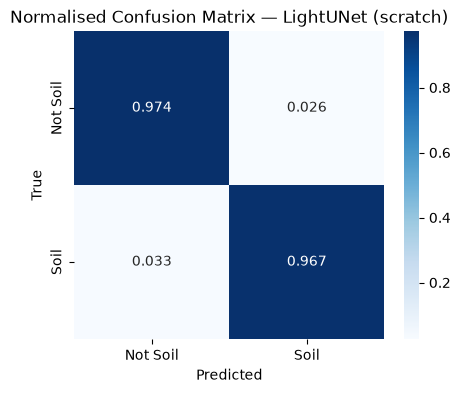

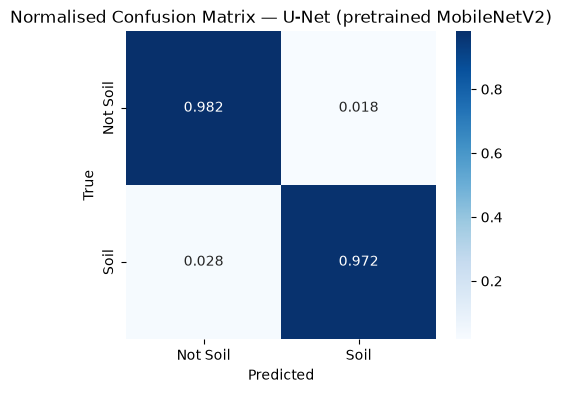

In [53]:
@torch.no_grad()
def collect_predictions(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device,
    threshold: float = 0.5,
) -> Tuple[np.ndarray, np.ndarray]:
    """Collect flat arrays of predicted and ground-truth pixel labels for a full dataset.

    Intended for building confusion matrices over all pixels in a split.

    Args:
        model (nn.Module): Segmentation model.
        loader (DataLoader): Dataloader yielding ``(images, masks)`` batches.
        device (torch.device): Device for inference.
        threshold (float): Sigmoid threshold for binarising predictions. Default: ``0.5``.

    Returns:
        Tuple[np.ndarray, np.ndarray]:
            - ``all_preds``:   Flat 1-D array of predicted pixel labels (0 or 1).
            - ``all_targets``: Flat 1-D array of ground-truth pixel labels (0 or 1).
    """
    model.eval()
    all_preds, all_targets = [], []
    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        logits = model(images)
        preds = (torch.sigmoid(logits) > threshold).float().cpu().numpy()
        all_preds.append(preds.reshape(-1))
        all_targets.append(masks.numpy().reshape(-1))
    return np.concatenate(all_preds), np.concatenate(all_targets)


def plot_confusion(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device,
    title: str,
) -> None:
    """Plot a normalised pixel-level confusion matrix for binary soil segmentation.

    Args:
        model (nn.Module): Trained segmentation model.
        loader (DataLoader): Dataloader for the evaluation split.
        device (torch.device): Device for inference.
        title (str): Plot title.
    """
    preds, targets = collect_predictions(model, loader, device)
    # normalize="true" → rows sum to 1 (recall per class); shows class-conditional error rates.
    cm = confusion_matrix(targets, preds, normalize="true")
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt=".3f",
        cmap="Blues",
        xticklabels=["Not Soil", "Soil"],
        yticklabels=["Not Soil", "Soil"],
    )
    plt.title(f"Normalised Confusion Matrix — {title}")
    plt.ylabel("True")
    plt.xlabel("Predicted")
    plt.show()


plot_confusion(model_scratch, test_loader, DEVICE, "LightUNet (scratch)")
plot_confusion(model_pretrained, test_loader, DEVICE, "U-Net (pretrained MobileNetV2)")

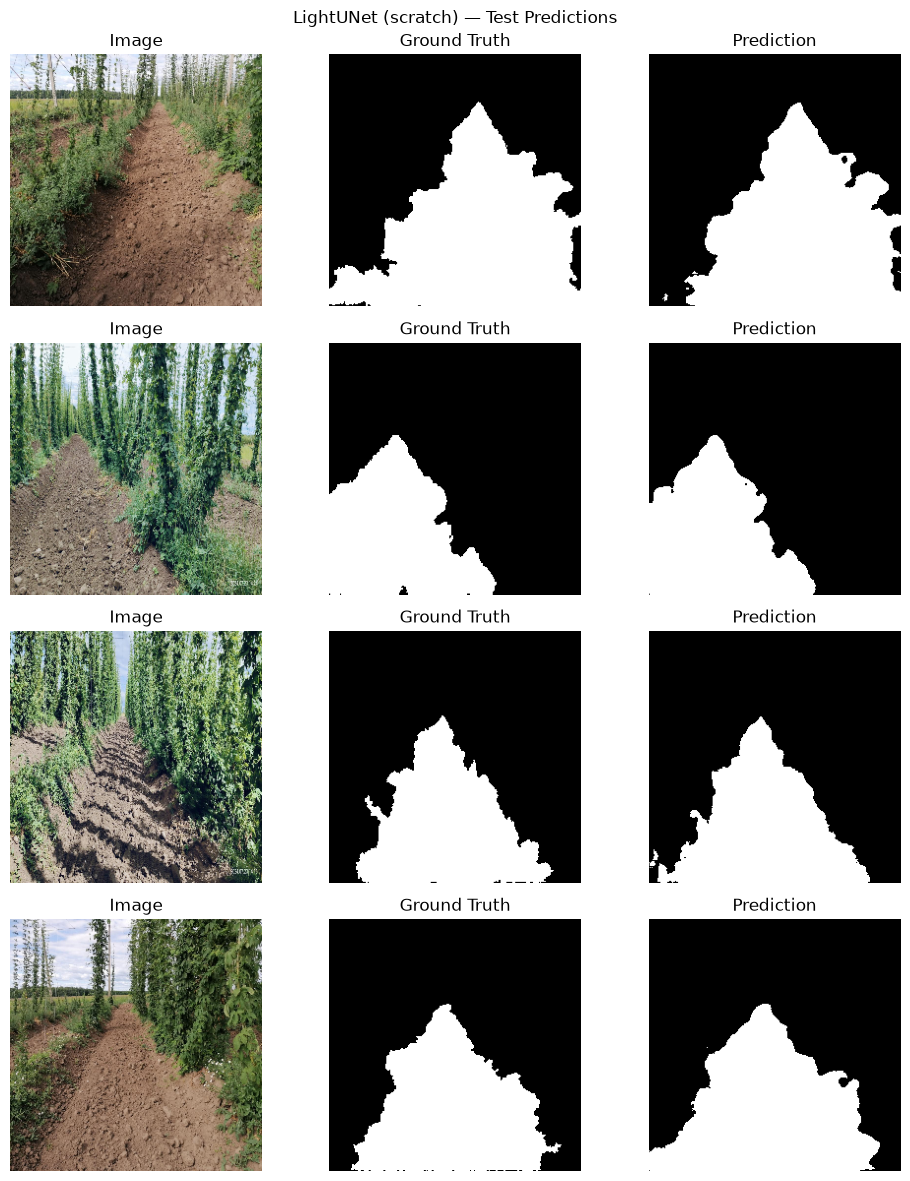

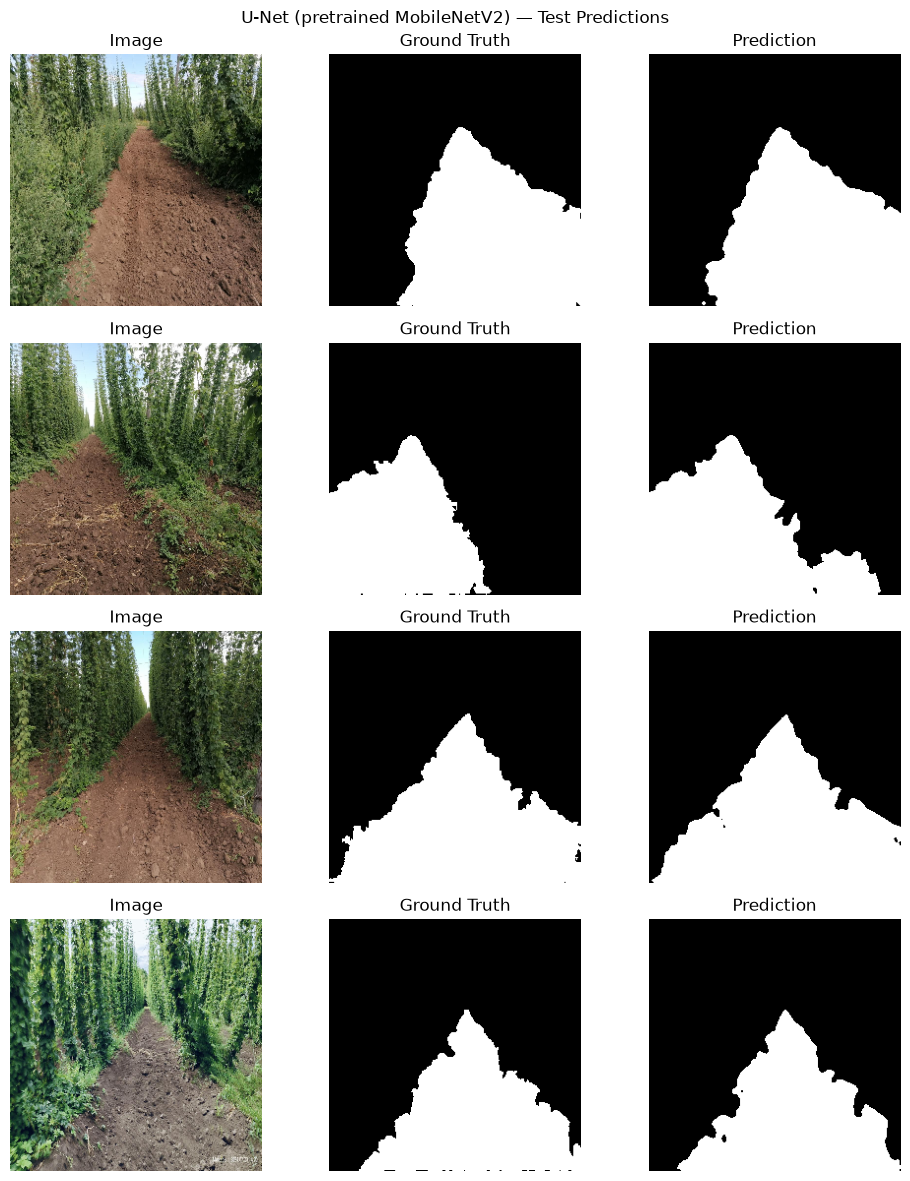

In [54]:
@torch.no_grad()
def show_predictions(
    model: nn.Module,
    dataset: Dataset,
    device: torch.device,
    n: int = 4,
    title: str = "",
) -> None:
    """Display a grid of (image | ground truth | prediction) triplets.

    Randomly samples ``n`` examples from ``dataset``, runs inference, and renders
    each sample as a row with three columns: the input image, the ground-truth mask,
    and the predicted binary mask.

    Args:
        model (nn.Module): Segmentation model.
        dataset (Dataset): Dataset to sample from (uses ``__getitem__``).
        device (torch.device): Device for inference.
        n (int): Number of samples to visualise. Default: ``4``.
        title (str): Figure super-title. Default: ``""``.
    """
    model.eval()
    idxs = random.sample(range(len(dataset)), n)
    fig, axes = plt.subplots(n, 3, figsize=(10, 3 * n))
    for row, idx in enumerate(idxs):
        image, mask = dataset[idx]
        # unsqueeze(0) adds a batch dimension before forwarding through the model.
        logits = model(image.unsqueeze(0).to(device))
        pred = (torch.sigmoid(logits) > 0.5).float().cpu()[0, 0]

        axes[row, 0].imshow(denormalize(image))
        axes[row, 0].set_title("Image")
        axes[row, 1].imshow(mask[0], cmap="gray")
        axes[row, 1].set_title("Ground Truth")
        axes[row, 2].imshow(pred, cmap="gray")
        axes[row, 2].set_title("Prediction")
        for ax in axes[row]:
            ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_predictions(
    model_scratch, test_ds, DEVICE, n=4, title="LightUNet (scratch) — Test Predictions"
)
show_predictions(
    model_pretrained,
    test_ds,
    DEVICE,
    n=4,
    title="U-Net (pretrained MobileNetV2) — Test Predictions",
)

## 15. Discussion and Conclusion

### Results Summary

| Model | Test Loss | Test IoU | Test Dice | Latency (ms/img) | Params (M) |
|---|---|---|---|---|---|
| LightUNet (scratch) | 0.0674 | 0.9147 | 0.9541 | 6.96 | 0.39 |
| U-Net (pretrained MobileNetV2) | 0.0511 | 0.9354 | 0.9641 | 10.93 | 6.63 |

### Speed vs. Accuracy Trade-off

The central design goal of this experiment was to favour inference speed and model compactness. Both models succeed on that front: LightUNet, at only **0.39 M parameters**, is 17× smaller than the MobileNetV2-backed model (6.63 M) and runs at **6.96 ms/image** — 36% faster than the pretrained variant's 10.93 ms/image. For a deployment context such as an onboard robot running at 10–30 Hz, both speeds are viable, but LightUNet's headroom is clearly larger and leaves compute budget for other pipeline stages (localisation, planning, etc.).

The accuracy cost of this compactness is real but modest. LightUNet achieves a test IoU of **0.915** and test Dice of **0.954**, while the MobileNetV2 model reaches **0.935** IoU and **0.964** Dice — an absolute gap of approximately 2 IoU points and 1 Dice point. For a binary segmentation task on relatively structured agricultural imagery (consistent soil texture, clear path boundaries), a 0.915 IoU from a model trained from scratch with 0.39 M parameters is a strong result. The gap is narrow enough that LightUNet could be the preferred choice whenever latency or memory are hard constraints.

## Transfer Learning Benefit

The benefit of the pretrained MobileNetV2 encoder is visible from the very first epoch. At epoch 1, the pretrained model already reaches a validation IoU of **0.906** and Dice of **0.947**, whereas LightUNet starts at IoU **0.837** and Dice **0.905** — a gap of roughly 4 Dice points before the decoder has even seen a second update. This confirms the expected advantage of ImageNet features for low-data regimes: the encoder arrives with robust low-level edge and texture detectors that transfer well to the soil/vegetation boundary discrimination task.

The 5-epoch warm-up schedule worked as intended. During epochs 1–5, only the decoder is trained; the validation loss falls steadily from 0.087 to 0.069 without any instability. At epoch 6, the encoder is unfrozen at a 10× reduced learning rate, which triggers an immediate further jump in validation Dice (0.956 → 0.960 by epoch 7), confirming that the decoder had learned to consume the pretrained features before end-to-end gradients were applied. No loss spike or divergence occurred at the unfreeze transition — evidence that the conservative learning rate differential was appropriate.

## Convergence Behaviour

**LightUNet (scratch):** Both loss curves descend smoothly and track each other closely throughout all 25 epochs, with the training loss ending slightly above the validation loss (0.088 vs. 0.077 at epoch 25). This is an unusual but healthy pattern — it typically indicates that the augmentations applied during training (flips, rotations, brightness/contrast jitter) make the training objective harder than the clean evaluation objective, so the model is not overfitting. The model continued to improve incrementally through epoch 25, saving a new best at epoch 22 (Dice 0.9486); additional epochs would likely yield further small gains.

**U-Net (pretrained MobileNetV2):** The pretrained model converges faster and to a lower loss, but from epoch ~13 onward the training loss continues to fall (0.063 → 0.051) while the validation loss plateaus around 0.060. This small and growing train/val gap is the first sign of mild overfitting — the encoder's large capacity (6.63 M params) begins to fit dataset-specific features that do not generalise. The gap remains small enough that test performance is unaffected (test Dice 0.964 aligns with the best validation Dice of 0.961), but extending training beyond 25 epochs without additional regularisation (e.g., stronger augmentation or dropout in the decoder) would risk widening it.

`ReduceLROnPlateau` did not fire visibly for either model within 25 epochs, which means the chosen patience of 3 epochs was never triggered — consistent with both loss curves showing sustained, if slow, improvement throughout training.


## Error Pattern Analysis

The confusion matrices reinforce the quantitative results. Both models are well-balanced: neither systematically confuses soil for background nor background for soil at a high rate.

**LightUNet (scratch):** Background recall 97.5%, soil recall 96.4%. The false-negative rate on soil (3.6%) is slightly higher than the false-positive rate (2.5%), meaning the model is marginally more likely to miss a soil pixel than to label a non-soil pixel as soil. This is consistent with the known challenge of ambiguous boundaries between sparse vegetation and bare patches of soil: the small model sometimes errs on the side of predicting background when texture evidence is weak.

**U-Net (pretrained MobileNetV2):** Background recall 98.0%, soil recall 97.6%. Both error rates are 1–1.5 percentage points lower than LightUNet's, and the asymmetry between FNR and FPR is reduced (2.4% vs. 2.0%), suggesting the pretrained encoder's richer feature representation helps the decoder resolve ambiguous boundary regions more confidently. Critically for the autonomous navigation application — where driving into crop rows is more damaging than a slightly narrower perceived path — the soil false-negative rate of 2.4% is low enough to be operationally acceptable.

## Limitations and Future Directions

**Resolution trade-off.** Both models operate on 256×256 inputs downsampled from 1024×1024 originals. Fine boundary details at the edges of paths — where soil gradually transitions into root mats or low weeds — are partially lost at this resolution. Training at 512×512 with mixed precision would roughly double memory requirements but could recover precision in these ambiguous zones.

**Quantisation.** LightUNet's depthwise-separable architecture is well-suited to INT8 post-training quantisation (PTQ), which would roughly halve memory bandwidth and further reduce latency on edge hardware (e.g., Jetson Nano, Raspberry Pi + Coral). At 0.39 M parameters the model is small enough that quantisation accuracy degradation is typically under 1 Dice point.

**Attention gates on skip connections.** Adding a lightweight channel or spatial attention gate to each skip connection would allow the decoder to suppress irrelevant encoder features (e.g., trellis wire textures) while amplifying soil-edge cues, at a marginal parameter cost.

**Longer training / cosine annealing.** LightUNet showed no sign of convergence saturation at epoch 25. Replacing `ReduceLROnPlateau` with a cosine annealing schedule over 50–75 epochs would likely close part of the remaining gap to the pretrained model without any architecture changes.

## Conclusion

Both models successfully solve the binary soil-path segmentation task at a level that is practically useful for precision agriculture applications. The **LightUNet trained from scratch** (0.39 M params, 6.96 ms/image, test IoU 0.915) demonstrates that a carefully designed lightweight architecture — built on depthwise-separable convolutions — can achieve strong segmentation performance without any pretrained weights, making it suitable for offline or resource-constrained deployment. The **U-Net with pretrained MobileNetV2 encoder** (6.63 M params, 10.93 ms/image, test IoU 0.935) provides a meaningful accuracy boost through transfer learning at the cost of 57% higher latency and a 17× larger parameter footprint, and is the better choice when a GPU inference server is available.

The experiment confirms two broader lessons: (1) depthwise-separable convolutions are an effective and underused tool for building small segmentation models in agricultural vision; and (2) a conservative warm-up + fine-tune schedule for pretrained encoders — decoder-first for 5 epochs, then end-to-end at a 10× lower encoder LR — transfers cleanly to domain-specific segmentation without instability at the unfreeze boundary.

## References

[1] Evgeny, "Spray Hops Computer Vision Dataset," Roboflow Universe, 2024.
    Available: https://universe.roboflow.com/evgeny-5zgzy/spray-hops/dataset/1. License: CC BY 4.0.

[2] O. Ronneberger, P. Fischer, and T. Brox, "U-Net: Convolutional Networks for
    Biomedical Image Segmentation," 2015.

[3] A. G. Howard et al., "MobileNets: Efficient Convolutional Neural Networks for Mobile
    Vision Applications," 2017.

[4] M. Sandler et al., "MobileNetV2: Inverted Residuals and Linear Bottlenecks," CVPR 2018.

[5] P. Iakubovskii, "Segmentation Models PyTorch," GitHub repository, 2019.
    Available: https://github.com/qubvel/segmentation_models.pytorch
